Start > Bot > Answer mode > short, long, medium > end

         Start
            |
         Question
          /  |  \
    short  medium  long
            |
            Bot
            |
            Answer
            |
            END

### 1. LLM

In [1]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
load_dotenv()


def get_llm():
    return ChatOpenAI(
    model="qwen/qwen3.8-max:free",
    base_url="https://api.xkiro.com/v1",
    api_key=os.getenv("XKIRO_API_KEY"),
    temperature=0.2,
    max_tokens=1000
)

In [2]:
get_llm().invoke("hy")

AIMessage(content='Hi. How can I help you?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 175, 'total_tokens': 183, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'qwen/qwen3.8-max:free', 'system_fingerprint': None, 'id': 'chatcmpl-49c83336-825d-45bb-8d87-eb3b0bdc315d', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17b4b-eb15-71d1-b3c2-8d7ff0345e4a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 175, 'output_tokens': 8, 'total_tokens': 183, 'input_token_details': {}, 'output_token_details': {}})

### 2. Define state

In [2]:
from typing import TypedDict

class BotState(TypedDict, total=False):
    
    question: str
    bot_response: str
    answer_mode: str

### 3. Node

In [3]:
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.types import interrupt, Command


def Ask_Agent(state: BotState):

    answer_mode = interrupt(
        {
            "message": "Choose Your Answer Length",
            "Options": ["Short", "Medium", "Long"]
        }
    )

    llm = get_llm()
    system_prompt = f"""
        You are an expert AI Doubt Solver. Help students understand concepts clearly.

        Detail Level Instruction: {answer_mode}

        General Guidelines:
        1. Ensure high technical accuracy and clarity.
        2. Break down complex points step-by-step.
        3. Avoid unnecessary filler text.
    """

    response = llm.invoke(
        [
            SystemMessage(
                content=system_prompt
            ),
            HumanMessage(
                content=state["question"]
            )
        ]
    )

    return {"bot_response": response.content}


# def interrupt_node(state: BotState):
#    response = interrupt(
#         {
#             "message": "Choose Your Answer Length",
#             "Options": ["Short", "Medium", "Long"]
#         }
#     )
#    return {"answer_mode": response}

### 4. Build Graph

In [4]:
from langgraph.graph import START, END, StateGraph
from langgraph.checkpoint.memory import InMemorySaver

def agent_graph():

    graph = StateGraph(BotState)

    # Nodes
    graph.add_node("bot_node", Ask_Agent)

    # Edges
    graph.add_edge(START, "bot_node")
    graph.add_edge("bot_node", END)

    return graph.compile(checkpointer=InMemorySaver())

graph = agent_graph()

config = {
    "configurable": {
        "thread_id": "doubt-1"
    }
}


### Invoke Chat

In [5]:
result = graph.invoke(
    {"question": "What is the diffrence between of python list or tuple"},
    config=config
)

In [9]:
result['__interrupt__'][0].value

{'message': 'Choose Your Answer Length',
 'Options': ['Short', 'Medium', 'Long']}

In [ ]:
state = graph.get_state(config)
pending = any(t.interrupts for t in state.tasks)

In [ ]:
for t in state.tasks:
    print(t.interrupts)

(Interrupt(value={'message': 'Choose Your Answer Length', 'Options': ['Short', 'Medium', 'Long']}, id='cd23a4eb3f7d657093c01a802cbca22d'),)


In [ ]:
print(state)

StateSnapshot(values={'question': 'What is the diffrence between of python list or tuple'}, next=('bot_node',), config={'configurable': {'thread_id': 'doubt-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caa88-40ed-658b-8000-0cc78f65df90'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-18T04:00:54.407719+00:00', parent_config={'configurable': {'thread_id': 'doubt-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1caa88-40db-6af0-bfff-c056675132f7'}}, tasks=(PregelTask(id='27799cce-af9f-b842-c420-df437ce99272', name='bot_node', path=('__pregel_pull', 'bot_node'), error=None, interrupts=(Interrupt(value={'message': 'Choose Your Answer Length', 'Options': ['Short', 'Medium', 'Long']}, id='cd23a4eb3f7d657093c01a802cbca22d'),), state=None, result=None),), interrupts=(Interrupt(value={'message': 'Choose Your Answer Length', 'Options': ['Short', 'Medium', 'Long']}, id='cd23a4eb3f7d657093c01a802cbca22d'),))


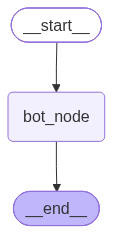

In [ ]:
graph

In [ ]:
result = graph.invoke(Command(resume="short"), config=config)
result

{'question': 'What is the diffrence between of python list or tuple',
 'bot_response': '**List vs Tuple in Python**\n\n| Feature | List | Tuple |\n|---|---|---|\n| **Syntax** | `[1, 2, 3]` | `(1, 2, 3)` |\n| **Mutability** | Mutable (can be changed) | Immutable (cannot be changed) |\n| **Performance** | Slower | Faster |\n| **Memory** | Uses more memory | Uses less memory |\n| **Dictionary Keys** | Cannot be used as keys | Can be used as keys |\n| **Methods** | Many (`append`, `remove`, etc.) | Few (`count`, `index`) |\n\n**Key takeaway:** Use a list when you need to modify the data. Use a tuple when the data should remain constant.'}

In [ ]:
print(result['bot_response'])

**List vs Tuple in Python**

| Feature | List | Tuple |
|---|---|---|
| **Syntax** | `[1, 2, 3]` | `(1, 2, 3)` |
| **Mutability** | Mutable (can be changed) | Immutable (cannot be changed) |
| **Performance** | Slower | Faster |
| **Memory** | Uses more memory | Uses less memory |
| **Dictionary Keys** | Cannot be used as keys | Can be used as keys |
| **Methods** | Many (`append`, `remove`, etc.) | Few (`count`, `index`) |

**Key takeaway:** Use a list when you need to modify the data. Use a tuple when the data should remain constant.


In [ ]:
from huggingface_hub import snapshot_download

model_path = snapshot_download(
    repo_id="sentence-transformers/all-MiniLM-L6-v2",
    local_dir=r"D:\Downloads\LLM_MODELS\all-MiniLM-L6-v2",
    token=""
)

print("Model downloaded successfully!")
print("Saved at:", model_path)

Fetching 30 files:   0%|          | 0/30 [00:00<?, ?it/s]

Model downloaded successfully!
Saved at: D:\Downloads\LLM_MODELS\all-MiniLM-L6-v2
